In [1]:
source(here::here('MG3.functions1.R'))


In [2]:
suppressMessages({
    library(rCBA)
    library(arules)
    library(Matrix)
    library(mltools)
    library(sparseMatrixStats)
    }
)
apriori_rulesfname=paste0(OutputDir, "/RulesCompliantInKeySpeciesMatrix/apriori_rules5BM.RDS")


# Retrieving the transaction data from SQL

In [3]:
allTransactionsList=list()
queryTxt='SELECT CAST(transactionID AS int) AS transactionID, specie_gene_id AS ensembl_gene_id 
FROM keySpBijectiveGenesTransactions5MB WHERE specie="hsapiens"'
allTransactionsDF=dbGetQuery(mydbRO, queryTxt)
allTransactionsDFspecie=allTransactionsDF
allTransactionsDFspecie$specie="hsapiens"
allTransactionsList[["hsapiens"]]=allTransactionsDFspecie

for (sp in relevantSpecies){
    message(sp)
    queryTxt=sprintf('SELECT CAST(transactionID AS int) AS transactionID, ensembl_gene_id 
FROM keySpBijectiveGenesTransactions5MB 
INNER JOIN homology ON keySpBijectiveGenesTransactions5MB.specie_gene_id = homology.homolog
WHERE keySpBijectiveGenesTransactions5MB.specie="%s"',sp)
    tmpTransactionsDF=dbGetQuery(mydbRO, queryTxt)
    allTransactionsDF=rbind(allTransactionsDF, tmpTransactionsDF)
    
    tmpTransactionsDFspecie=tmpTransactionsDF
    tmpTransactionsDFspecie$specie=sp
    allTransactionsList[[sp]]=tmpTransactionsDFspecie
    allTransactionsDFspecie=rbind(allTransactionsDFspecie, tmpTransactionsDFspecie)
}

mmusculus

clfamiliaris

fcatus

btaurus

cdromedarius

lafricana

sscrofa

bmusculus



In [4]:
allTransactionsDFsum= allTransactionsDF %>% group_by(transactionID) %>% summarize(genes=list(ensembl_gene_id)) %>% as.data.table()

In [5]:
allTransactionsObj=as(allTransactionsDFsum$genes, 'transactions')

In [6]:
geneFactors=unique(allTransactionsDF$ensembl_gene_id)

## transactions obj properties

In [7]:
sizeP <- size(allTransactionsObj)
max(sizeP)

[1] 176

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


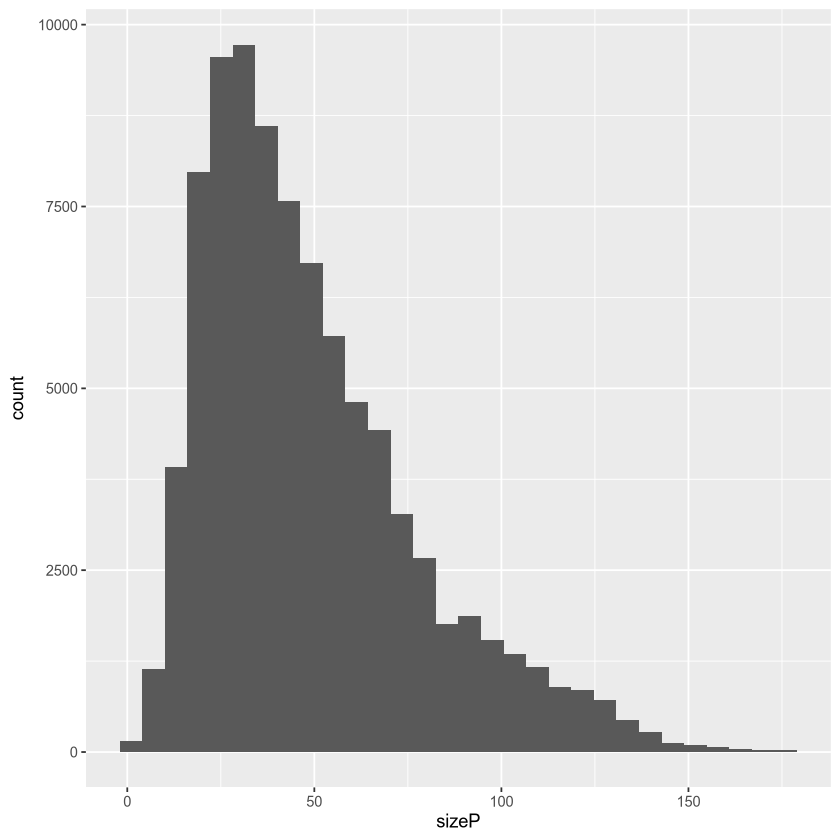

In [8]:
ggplot(NULL, aes(x=sizeP))+geom_histogram()

In [9]:
summary(allTransactionsObj)


transactions as itemMatrix in sparse format with
 87571 rows (elements/itemsets/transactions) and
 9754 columns (items) and a density of 0.005049493 

most frequent items:
ENSG00000141837 ENSG00000132004 ENSG00000105576 ENSG00000095059 ENSG00000123144 
           1135            1134            1133            1132            1131 
        (Other) 
        4307448 

element (itemset/transaction) length distribution:
sizes
   1    2    3    4    5    6    7    8    9   10   11   12   13   14   15   16 
  18   21   55   56  103  110  165  240  252  268  324  467  579  740  897  918 
  17   18   19   20   21   22   23   24   25   26   27   28   29   30   31   32 
1124 1261 1461 1315 1428 1388 1551 1632 1598 1607 1566 1608 1690 1671 1605 1593 
  33   34   35   36   37   38   39   40   41   42   43   44   45   46   47   48 
1534 1634 1559 1621 1451 1372 1288 1314 1504 1267 1301 1113 1232 1153 1244 1161 
  49   50   51   52   53   54   55   56   57   58   59   60   61   62   63   64 
1075 10

In [10]:
min(itemFrequency(allTransactionsObj))

[1] 0.0005823846

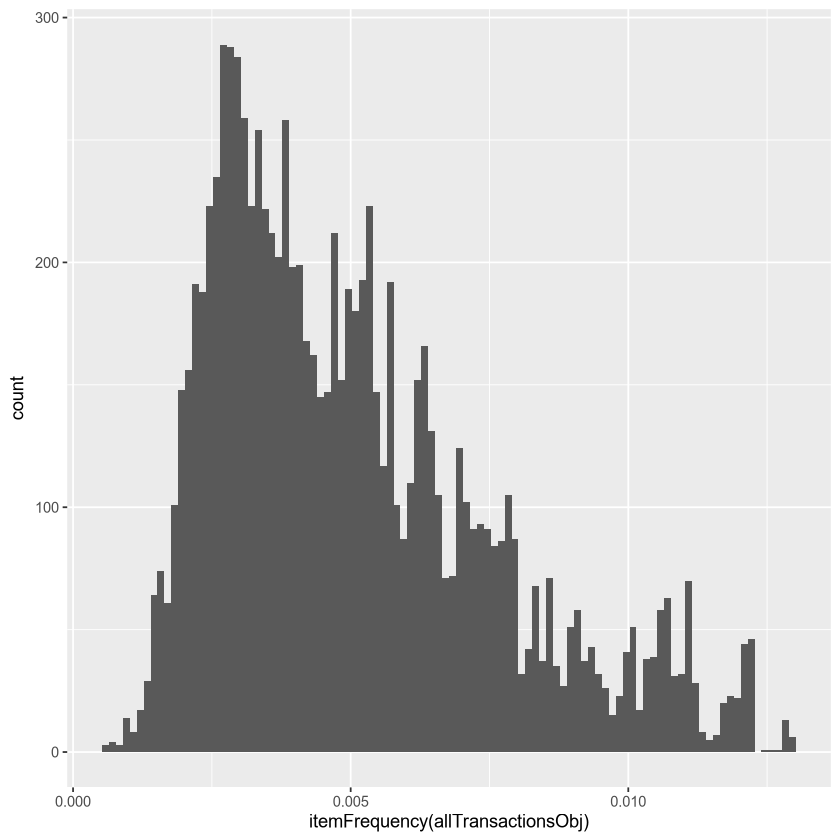

In [11]:
ggplot(NULL, aes(x=itemFrequency(allTransactionsObj)))+geom_histogram(bins=100)

In [12]:
apriori_rules <- apriori(allTransactionsObj, parameter = list(support = 1.25e-5, confidence = 1-(1/(length(relevantSpecies)+1)), 
                                                              minlen = 2, maxlen = 3, maxtime=120,
                                                                 target="rules"))

Apriori

Parameter specification:
 confidence minval smax arem  aval originalSupport maxtime  support minlen
  0.8888889    0.1    1 none FALSE            TRUE     120 1.25e-05      2
 maxlen target  ext
      3  rules TRUE

Algorithmic control:
 filter tree heap memopt load sort verbose
    0.1 TRUE TRUE  FALSE TRUE    2    TRUE

Absolute minimum support count: 1 

set item appearances ...[0 item(s)] done [0.00s].
set transactions ...[9754 item(s), 87571 transaction(s)] done [0.91s].
sorting and recoding items ... [9754 item(s)] done [0.05s].
creating transaction tree ... done [0.05s].
checking subsets of size 1 2 3

Warning message in apriori(allTransactionsObj, parameter = list(support = 1.25e-05, :
“Mining stopped (maxlen reached). Only patterns up to a length of 3 returned!”


 done [14.33s].
writing ... [47175853 rule(s)] done [6.44s].
creating S4 object  ... done [7.35s].


In [13]:
summary(apriori_rules)

set of 47175853 rules

rule length distribution (lhs + rhs):sizes
       2        3 
  122908 47052945 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  2.000   3.000   3.000   2.997   3.000   3.000 

summary of quality measures:
    support            confidence        coverage              lift        
 Min.   :2.284e-05   Min.   :0.8889   Min.   :2.284e-05   Min.   :  68.58  
 1st Qu.:1.827e-04   1st Qu.:1.0000   1st Qu.:1.827e-04   1st Qu.: 101.00  
 Median :5.139e-04   Median :1.0000   Median :5.139e-04   Median : 140.56  
 Mean   :1.365e-03   Mean   :0.9887   Mean   :1.392e-03   Mean   : 163.25  
 3rd Qu.:1.393e-03   3rd Qu.:1.0000   3rd Qu.:1.416e-03   3rd Qu.: 195.43  
 Max.   :1.294e-02   Max.   :1.0000   Max.   :1.296e-02   Max.   :1717.08  
     count       
 Min.   :   2.0  
 1st Qu.:  16.0  
 Median :  45.0  
 Mean   : 119.6  
 3rd Qu.: 122.0  
 Max.   :1133.0  

mining info:
               data ntransactions  support confidence
 allTransactionsObj         87571 1.25e-0

In [14]:
exportRuleToSQL=function(exportRuleSet){
    tmpLHSdata=as(exportRuleSet@lhs@data, "TsparseMatrix")
    tmpRHSdata=as(exportRuleSet@rhs@data, "TsparseMatrix")
    
    if (! all(exportRuleSet@lhs@itemInfo$labels == exportRuleSet@rhs@itemInfo$labels)){
        stop("LHS gene labels not equal RHS labels")
    }
    Nmembers=colSums(tmpLHSdata) +1
    
    
    LHSdt=data.table(ruleID=tmpLHSdata@j, LHSgeneFactor=tmpLHSdata@i )
    rawNmembers=Nmembers[LHSdt$ruleID +1]
    LHSdt$numMembers=rawNmembers
    setkey(LHSdt, "ruleID")
    RHSdt=data.table(ruleID=tmpRHSdata@j, RHSgeneFactor=tmpRHSdata@i )
    setkey(RHSdt, "ruleID")
    RulesDT=merge(LHSdt, RHSdt, by="ruleID")
    
    GeneFactorDF = data.frame(geneFactor=0:(nrow(exportRuleSet@lhs@itemInfo)-1), 
                              ensembl_gene_id= exportRuleSet@lhs@itemInfo$labels)

    if ("PassedAssociationGeneFactors5MB" %in% dbListTables(mydbRW)) dbExecute(mydbRW, 'DROP TABLE PassedAssociationGeneFactors5MB')   
    dbWriteTable(mydbRW, "PassedAssociationGeneFactors5MB", GeneFactorDF, append=FALSE)
    message("Factor table written ", getTimeStamp())
    dbExecute(mydbRW, 'CREATE INDEX IF NOT EXISTS PassedAssociationGeneFactors5MBInd ON PassedAssociationGeneFactors5MB(geneFactor)')
    dbExecute(mydbRW, 'CREATE INDEX IF NOT EXISTS PassedAssociationGeneFactors5MBENSidInd ON PassedAssociationGeneFactors5MB(ensembl_gene_id)')
    message("Factor table indexed ", getTimeStamp())
    
    if ("PassedAssociationRules5MB" %in% dbListTables(mydbRW)) dbExecute(mydbRW, 'DROP TABLE PassedAssociationRules5MB')
    dbWriteTable(mydbRW, "PassedAssociationRules5MB", RulesDT, append=FALSE)
    message("Rule table written ", getTimeStamp())
    dbExecute(mydbRW, 'CREATE INDEX IF NOT EXISTS AssociationRules5MBRuleInd ON PassedAssociationRules5MB(ruleID)')
    dbExecute(mydbRW, 'CREATE INDEX IF NOT EXISTS AssociationRules5MBLHSInd ON PassedAssociationRules5MB(LHSgeneFactor)')
    dbExecute(mydbRW, 'CREATE INDEX IF NOT EXISTS AssociationRules5MBRHSInd ON PassedAssociationRules5MB(RHSgeneFactor)')
    message("Rule table indexed ", getTimeStamp())
}

# Filtering the rules

In [15]:
lowerLimits=1
upperLimits=NULL
maxChunk=1e6
maxRuleID=apriori_rules@lhs@data@Dim[2]
while (max(lowerLimits)<maxRuleID){
    upperLimit=as.integer(min(max(lowerLimits)+maxChunk, maxRuleID))
    upperLimits=addToVec(upperLimits, upperLimit)
    lowerLimits=addToVec(lowerLimits, upperLimit+1)
}
lowerLimits=lowerLimits[ 1:(length(lowerLimits)-1)]
lowerLimits=as.integer(lowerLimits)
upperLimits=as.integer(upperLimits)

In [16]:
#creating directory for the matrix files
comToBash=paste0("mkdir -p ",OutputDir,"RulesCompliantInKeySpeciesMatrix/slurm_logs")
#message(comToBash)
system(comToBash, intern = FALSE, wait = TRUE)

saveRDS(apriori_rules, apriori_rulesfname)

allTransactionsDFspecieFname=paste0(OutputDir, "/RulesCompliantInKeySpeciesMatrix/allTransactionsDFspecie5BM.RDS")
saveRDS(allTransactionsDFspecie, allTransactionsDFspecieFname)



options(scipen = 999)
sbatchscript="/home/frimanav/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh /home/frimanav/data/lambda/notebooks/MG3.Step5.RulesComplianceMatrixCheck.R"
swarmlines=NULL 
for (i in 1:length(lowerLimits)){
    #message(lowerLimits[i],":", upperLimits[i])
    for (sp in c("hsapiens", relevantSpecies)){
        swarmline=paste(sbatchscript, allTransactionsDFspecieFname, apriori_rulesfname, lowerLimits[i], upperLimits[i], sp)
        swarmlines=addToVec(swarmlines, swarmline)
    }
}


length(swarmlines)

swarmparams=paste0("#SWARM -t 2 -g 80 --time=00:30:00 --gres=lscratch:10 --logdir ", path.expand(OutputDir),"RulesCompliantInKeySpeciesMatrix/slurm_logs/")
maxchunk=1000
timestamp=getTimeStamp()
processed=0
i=0
swarmFiles=NULL
while (processed<length(swarmlines)){
    upperlimit=processed+min(maxchunk, length(swarmlines)-processed)
    #message(paste(processed+1, upperlimit))
    fname=paste0(OutputDir,"RulesCompliantInKeySpeciesMatrix/runningMatrixCompliance.",i,"-", timestamp,".swarm")
    writeLines(text = c(swarmparams, swarmlines[(processed+1):upperlimit]), 
               con=fname)
    message("Run from bash: ", fname)
    swarmFiles=addToVec(swarmFiles, fname)
    processed=upperlimit
    i=i+1
}


[1] 432

Run from bash: ~/data/lambda/output/RulesCompliantInKeySpeciesMatrix/runningMatrixCompliance.0-2026-01-21_13.43.03.810122.swarm



## Summarize the passed rules accross the key species

In [17]:
sbatchscript="/home/frimanav/data/lambda/notebooks/Rscript.wrapper.lambdaenv.sh /home/frimanav/data/lambda/notebooks/MG3.Step5.RuleComplianceSummary.R"
swarmlines=NULL 
for (i in 1:length(lowerLimits)){
    swarmline=paste(sbatchscript, lowerLimits[i], upperLimits[i])
    swarmlines=addToVec(swarmlines, swarmline)

}
length(swarmlines)
swarmparams=paste0("#SWARM -t 1 -g 10 --time=00:45:00 --gres=lscratch:10 --logdir ", path.expand(OutputDir),"RulesCompliantInKeySpeciesMatrix/slurm_logs/")
maxchunk=1000
timestamp=getTimeStamp()
processed=0
i=0
swarmFiles=NULL
while (processed<length(swarmlines)){
    upperlimit=processed+min(maxchunk, length(swarmlines)-processed)
    #message(paste(processed+1, upperlimit))
    fname=paste0(OutputDir,"RulesCompliantInKeySpeciesMatrix/runningMatrixComplianceSummary.",i,"-", timestamp,".swarm")
    writeLines(text = c(swarmparams, swarmlines[(processed+1):upperlimit]), 
               con=fname)
    message("Run from bash: ", fname)
    swarmFiles=addToVec(swarmFiles, fname)
    processed=upperlimit
    i=i+1
}


[1] 48

Run from bash: ~/data/lambda/output/RulesCompliantInKeySpeciesMatrix/runningMatrixComplianceSummary.0-2026-01-21_14.24.12.339561.swarm



### Harvesting the results

In [18]:
AllRulesSum=NULL
for (f in list.files(path = paste0(OutputDir, "/RulesCompliantInKeySpeciesMatrix/"), 
                     pattern = "AllPassedRulesSum.*-.*.RDS", full.names = TRUE)){
    tmpDF=readRDS(f)
    AllRulesSum=addToDF(AllRulesSum,tmpDF)
}

In [19]:
all(AllRulesSum$Nspecies==AllRulesSum$N)

[1] TRUE

In [20]:
max(AllRulesSum$Nspecies)

[1] 9

In [21]:
min(AllRulesSum$Nspecies)

[1] 1

In [22]:
AllPassedRulesSum=AllRulesSum[ AllRulesSum$Nspecies>=length(relevantSpecies), ] # does not include human, thus 9-1 = 8 species

In [23]:
#apriori_rules=readRDS(apriori_rulesfname)


In [24]:
apriori_rulesPASSED=apriori_rules[AllPassedRulesSum$ruleID]

In [25]:
apriori_rulesPASSED

set of 3840354 rules 

In [26]:
exportRuleToSQL(apriori_rulesPASSED)

Factor table written 2026-01-21_14.33.11.589509

Factor table indexed 2026-01-21_14.33.11.625363

Rule table written 2026-01-21_14.33.15.239546

Rule table indexed 2026-01-21_14.33.26.54099



# Veryfying the results on the key species

In [27]:
source(here::here('MG3.functions1.R'))

HMMsToCheck=dbGetQuery(mydbRO, "SELECT DISTINCT ensembl_gene_id FROM HomologyBijectiveWellDefined")[[1]]

In [28]:
length(HMMsToCheck)

[1] 9754

In [29]:
#creating directory for the matrix files
comToBash=paste0("mkdir -p ",OutputDir,"RulesCompliantInKeySpeciesMatrix/keySpeciesVerification/slurm_logs")
#message(comToBash)
system(comToBash, intern = FALSE, wait = TRUE)

commandLines=paste("/home/frimanav/data/lambda/notebooks/MG3.Step5.CheckKeySpeciesCompliance.R", HMMsToCheck)
RcommandsFile=paste0(OutputDir,"RulesCompliantInKeySpeciesMatrix/keySpeciesVerification/Rcommands.txt")
writeLines(text = commandLines, con = RcommandsFile)

lowerLimits=1
upperLimits=NULL
maxChunk=15
endOfHMMvector=length(HMMsToCheck)
while (max(lowerLimits)<endOfHMMvector){
    upperLimit=as.integer(min(max(lowerLimits)+maxChunk, endOfHMMvector))
    upperLimits=addToVec(upperLimits, upperLimit)
    lowerLimits=addToVec(lowerLimits, upperLimit+1)
}
lowerLimits=lowerLimits[ 1:(length(lowerLimits)-1)]
lowerLimits=as.integer(lowerLimits)
upperLimits=as.integer(upperLimits)

options(scipen = 999)
sbatchscript="/home/frimanav/data/lambda/notebooks/Rscript.wrapper.serial.lambdaenv.sh "
swarmlines=NULL 
for (i in 1:length(lowerLimits)){
        swarmline=paste(sbatchscript, RcommandsFile, lowerLimits[i], upperLimits[i])
        swarmlines=addToVec(swarmlines, swarmline)
}


length(swarmlines)

swarmparams=paste0("#SWARM -t 2 -g 10 --time=01:00:00 --gres=lscratch:10 --logdir ", path.expand(OutputDir),"RulesCompliantInKeySpeciesMatrix/keySpeciesVerification/slurm_logs/")
maxchunk=1000
timestamp=getTimeStamp()
processed=0
i=0
swarmFiles=NULL
while (processed<length(swarmlines)){
    upperlimit=processed+min(maxchunk, length(swarmlines)-processed)
    #message(paste(processed+1, upperlimit))
    fname=paste0(OutputDir,"RulesCompliantInKeySpeciesMatrix/keySpeciesVerification/runningkeySpecieCompliance.",i,"-", timestamp,".swarm")
    writeLines(text = c(swarmparams, swarmlines[(processed+1):upperlimit]), 
               con=fname)
    message("Run from bash: ", fname)
    swarmFiles=addToVec(swarmFiles, fname)
    processed=upperlimit
    i=i+1
}



[1] 610

Run from bash: ~/data/lambda/output/RulesCompliantInKeySpeciesMatrix/keySpeciesVerification/runningkeySpecieCompliance.0-2026-01-21_14.33.40.703794.swarm



In [39]:
IDed_HMM_DF=data.frame(ensembl_gene_id=HMMsToCheck, found_in_species_numb=0)
for (i in 1:length(HMMsToCheck)){
    HMMid = HMMsToCheck[i]
    fname=paste0(OutputDir,"RulesCompliantInKeySpeciesMatrix/keySpeciesVerification/", HMMid, ".txt")
    if (! file.exists(fname)){
        message(HMMid)
    }else{
        IDed_HMM_DF$found_in_species_numb[i]=as.integer(readLines(con = fname))
    }
}

In [42]:
positively_IDed_DF = IDed_HMM_DF[ IDed_HMM_DF$found_in_species_numb== length(relevantSpecies)+1 ,]

In [44]:
nrow(positively_IDed_DF)

[1] 9608

In [43]:
dbWriteTable(mydbRW, "positively_ided_using_context", positively_IDed_DF, append=FALSE)
dbExecute(mydbRW, 'CREATE INDEX IF NOT EXISTS positively_ided_using_contentGeneInd ON positively_ided_using_context(ensembl_gene_id)')


[1] 0